#  Indian Facial Emotion Recognition — Custom Residual CNN v3
### (Final tuned variant — Offline Aug + Class Weight + balanced regularization)


---
##  Section 1 — Setup & GPU Check

In [1]:
# Check GPU availability
import tensorflow as tf
print("TensorFlow version:", tf.__version__)
gpu = tf.config.list_physical_devices('GPU')
if gpu:
    print(f"✅ GPU detected: {gpu[0].name}")
else:
    print("⚠️  No GPU found. Go to Runtime → Change runtime type → T4 GPU for faster training.")

TensorFlow version: 2.20.0
✅ GPU detected: /physical_device:GPU:0


In [2]:
# Install required libraries
!pip install -q tensorflow keras scikit-learn matplotlib seaborn

In [3]:
# Mount Google Drive (recommended to save model & data persistently)
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


---
## Section 2 — Download & Extract Dataset



In [4]:
# OPTION B: Copy from Google Drive (faster if you uploaded ZIP to Drive first)
import os

# Upload classified_dataset_m.zip to your Google Drive first (e.g. MyDrive root),
# then make sure the filename below matches exactly:
zip_filename = '/content/drive/MyDrive/classified_dataset_m.zip'
!cp "{zip_filename}" /content/
print(f"✅ Copied '{os.path.basename(zip_filename)}' from Drive")

✅ Copied 'classified_dataset_m.zip' from Drive


In [5]:
# Extract the ZIP file
import zipfile, os

extract_path = '/content/raw_dataset/'
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_filename, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("✅ Extraction complete!")
print("Contents:", os.listdir(extract_path))

✅ Extraction complete!
Contents: ['classified_dataset']


In [6]:
# Auto-detect the emotion folders inside the extracted dataset
import os

extract_path = '/content/raw_dataset/'
KNOWN_EMOTION_NAMES = ['anger', 'angry', 'happiness', 'happy', 'fear', 'sadness', 'sad',
                        'surprise', 'surprised', 'excited', 'thoughtfulness', 'thaughtful',
                        'neutral', 'disgust', 'confused']

dataset_root = None
for root, dirs, files in os.walk(extract_path):
    if any(d.lower() in KNOWN_EMOTION_NAMES for d in dirs):
        dataset_root = root
        break

if dataset_root:
    emotion_folders = [d for d in os.listdir(dataset_root) if os.path.isdir(os.path.join(dataset_root, d))]
    print(f"✅ Dataset root found: {dataset_root}")
    print(f"   Emotion folders detected ({len(emotion_folders)}): {emotion_folders}")
else:
    print("⚠️  Could not auto-detect. Please set dataset_root manually.")
    print("   Full structure:")
    for root, dirs, files in os.walk(extract_path):
        level = root.replace(extract_path, '').count(os.sep)
        indent = '  ' * level
        print(f"{indent}{os.path.basename(root)}/")

✅ Dataset root found: /content/raw_dataset/classified_dataset
   Emotion folders detected (6): ['Angry', 'Happy', 'Fear', 'Disgust', 'Sad', 'Neutral']


In [7]:
# ── Fix: pin to a known-stable OpenCV version (5.0.0 has a broken data/objdetect bug) ──
!pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless -q
!pip install opencv-python-headless==4.10.0.84 -q

import cv2
print("cv2 version:", cv2.__version__)
print("has_cascade:", hasattr(cv2, 'CascadeClassifier'))

cv2 version: 4.10.0
has_cascade: True


---
##  Section 2a — Check Whether Images Are Already Face-Cropped



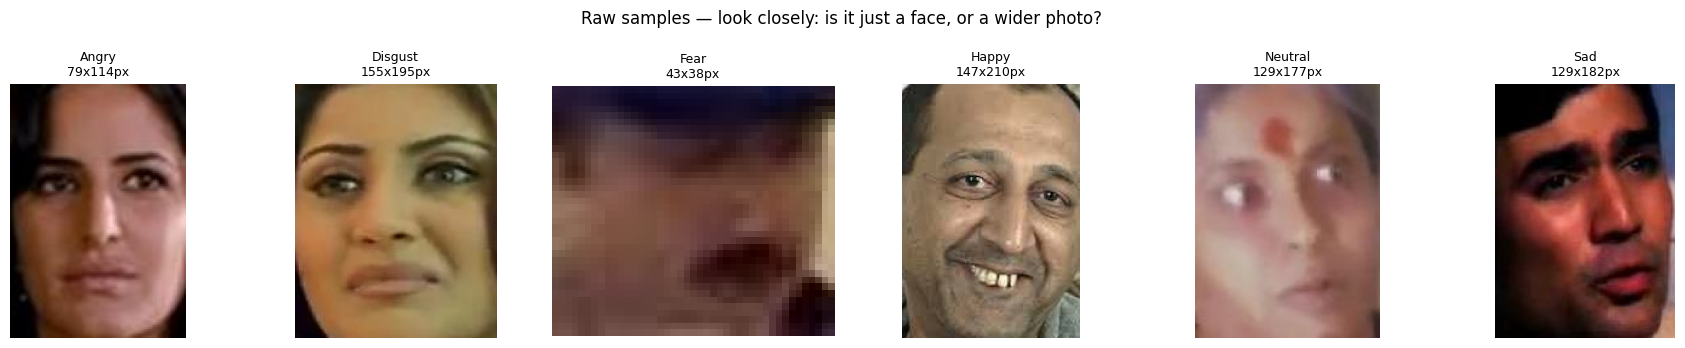

 FACE-CROP DIAGNOSTIC (sample of 300 images)
No face detected in     : 296/300 images (98.7%)
Mean face-to-image ratio: 34.9%  (100% = face fills the whole frame)

⚠️  Images do NOT appear consistently face-cropped — faces occupy a small/variable
   portion of the frame, and/or many images have no detectable face.
   Recommendation: add a face-cropping preprocessing step (crop every image to its
   detected face, matching what live_emotion.py does at inference time) before
   splitting/training, so the model sees a consistent input distribution.


In [8]:
import random
import cv2
import matplotlib.pyplot as plt
import numpy as np

sample_paths = []
for emotion in sorted(os.listdir(dataset_root)):
    class_dir = os.path.join(dataset_root, emotion)
    if not os.path.isdir(class_dir):
        continue
    files = [f for f in os.listdir(class_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]
    if files:
        sample_paths.append((emotion, os.path.join(class_dir, random.choice(files))))

# ── Visual check: look at raw (unresized) samples, one per class ────────────
n = len(sample_paths)
fig, axes = plt.subplots(1, n, figsize=(3 * n, 3.5))
for ax, (emotion, path) in zip(axes if n > 1 else [axes], sample_paths):
    img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.set_title(f"{emotion}\n{img.shape[1]}x{img.shape[0]}px", fontsize=9)
    ax.axis('off')
plt.suptitle("Raw samples — look closely: is it just a face, or a wider photo?", fontsize=12)
plt.tight_layout()
plt.show()

# ── Quantitative check: run a face detector over a larger random sample ─────
# This does NOT touch training data — it's a one-time diagnostic only.
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

all_paths = []
for emotion in sorted(os.listdir(dataset_root)):
    class_dir = os.path.join(dataset_root, emotion)
    if not os.path.isdir(class_dir):
        continue
    for f in os.listdir(class_dir):
        if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
            all_paths.append(os.path.join(class_dir, f))

sample = random.sample(all_paths, min(300, len(all_paths)))
face_area_ratios = []
no_face_count = 0

for path in sample:
    img = cv2.imread(path)
    if img is None:
        continue
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.2, minNeighbors=5, minSize=(30, 30))
    if len(faces) == 0:
        no_face_count += 1
        continue
    x, y, w, h = max(faces, key=lambda f: f[2] * f[3])  # largest detected face
    face_area = w * h
    img_area = img.shape[0] * img.shape[1]
    face_area_ratios.append(face_area / img_area)

print("=" * 55)
print(" FACE-CROP DIAGNOSTIC (sample of", len(sample), "images)")
print("=" * 55)
if face_area_ratios:
    mean_ratio = np.mean(face_area_ratios)
    print(f"No face detected in     : {no_face_count}/{len(sample)} images ({100*no_face_count/len(sample):.1f}%)")
    print(f"Mean face-to-image ratio: {mean_ratio*100:.1f}%  (100% = face fills the whole frame)")
    print()
    if mean_ratio > 0.55 and no_face_count / len(sample) < 0.1:
        print("✅ Images appear to already be tightly cropped to the face.")
        print("   No extra face-cropping preprocessing needed before training.")
    else:
        print("⚠️  Images do NOT appear consistently face-cropped — faces occupy a small/variable")
        print("   portion of the frame, and/or many images have no detectable face.")
        print("   Recommendation: add a face-cropping preprocessing step (crop every image to its")
        print("   detected face, matching what live_emotion.py does at inference time) before")
        print("   splitting/training, so the model sees a consistent input distribution.")
else:
    print("⚠️  No faces detected in the sample at all — inspect the visual grid above closely.")

### Fix — Crop Every Image to Its Detected Face



In [9]:
# Download OpenCV's DNN face detector (prototxt + weights) — a standard, small (~2.7MB) model
!wget -q -O /content/deploy.prototxt https://raw.githubusercontent.com/opencv/opencv/master/samples/dnn/face_detector/deploy.prototxt
!wget -q -O /content/res10_300x300_ssd_iter_140000.caffemodel https://raw.githubusercontent.com/opencv/opencv_3rdparty/dnn_samples_face_detector_20170830/res10_300x300_ssd_iter_140000.caffemodel

import os as _os
print("✅ Detector files ready:", _os.path.exists('/content/deploy.prototxt'),
      _os.path.exists('/content/res10_300x300_ssd_iter_140000.caffemodel'))

✅ Detector files ready: True True


In [10]:
import cv2, shutil
from tqdm.notebook import tqdm

CROPPED_DIR    = '/content/cropped_dataset/'
MARGIN         = 0.3    # extra padding around the detected face box, as a fraction of face size
CONF_THRESHOLD = 0.5    # minimum DNN confidence to accept a detection

net = cv2.dnn.readNetFromCaffe('/content/deploy.prototxt', '/content/res10_300x300_ssd_iter_140000.caffemodel')

if os.path.exists(CROPPED_DIR):
    shutil.rmtree(CROPPED_DIR)
os.makedirs(CROPPED_DIR, exist_ok=True)

# Build the full file list first so tqdm can show a real progress bar / ETA
all_jobs = []
for emotion in sorted(os.listdir(dataset_root)):
    src_dir = os.path.join(dataset_root, emotion)
    if not os.path.isdir(src_dir):
        continue
    os.makedirs(os.path.join(CROPPED_DIR, emotion), exist_ok=True)
    for fname in os.listdir(src_dir):
        if fname.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
            all_jobs.append((emotion, fname))

detected_count = 0
fallback_count = 0
unreadable_count = 0
fallback_by_class = {}

for emotion, fname in tqdm(all_jobs, desc="Face-cropping", unit="img"):
    fpath = os.path.join(dataset_root, emotion, fname)
    img = cv2.imread(fpath)
    if img is None:
        unreadable_count += 1
        continue

    h0, w0 = img.shape[:2]
    blob = cv2.dnn.blobFromImage(cv2.resize(img, (300, 300)), 1.0, (300, 300),
                                  (104.0, 177.0, 123.0))
    net.setInput(blob)
    detections = net.forward()

    best_conf = 0.0
    best_box = None
    for i in range(detections.shape[2]):
        conf = float(detections[0, 0, i, 2])
        if conf > best_conf:
            box = detections[0, 0, i, 3:7] * [w0, h0, w0, h0]
            best_conf, best_box = conf, box.astype(int)

    if best_box is not None and best_conf >= CONF_THRESHOLD:
        x1, y1, x2, y2 = best_box
        w, h = x2 - x1, y2 - y1
        pad_w, pad_h = int(w * MARGIN), int(h * MARGIN)
        x1, y1 = max(0, x1 - pad_w), max(0, y1 - pad_h)
        x2, y2 = min(w0, x2 + pad_w), min(h0, y2 + pad_h)
        detected_count += 1
    else:
        # Fallback: center-crop the largest square region instead of dropping the image
        side = min(h0, w0)
        cx, cy = w0 // 2, h0 // 2
        x1, y1 = max(0, cx - side // 2), max(0, cy - side // 2)
        x2, y2 = min(w0, cx + side // 2), min(h0, cy + side // 2)
        fallback_count += 1
        fallback_by_class[emotion] = fallback_by_class.get(emotion, 0) + 1

    face_crop = img[y1:y2, x1:x2]
    cv2.imwrite(os.path.join(CROPPED_DIR, emotion, fname), face_crop)

print("=" * 55)
print(" FACE-CROP PREPROCESSING RESULTS")
print("=" * 55)
print(f"✅ Face detected & cropped : {detected_count} images")
print(f"↪️  Fallback (center-crop) : {fallback_count} images")
print(f"❌ Unreadable (skipped)    : {unreadable_count} images")
if fallback_by_class:
    print("\nFallback usage per class:")
    for emotion, n in sorted(fallback_by_class.items()):
        print(f"  {emotion:>15s}: {n}")

# All downstream steps (dedup, split, training) now use the face-cropped dataset
dataset_root = CROPPED_DIR
print(f"\n✅ dataset_root now points to: {dataset_root}")

Face-cropping:   0%|          | 0/39902 [00:00<?, ?img/s]

 FACE-CROP PREPROCESSING RESULTS
✅ Face detected & cropped : 33223 images
↪️  Fallback (center-crop) : 6679 images
❌ Unreadable (skipped)    : 0 images

Fallback usage per class:
            Angry: 721
          Disgust: 18
             Fear: 161
            Happy: 1303
          Neutral: 4247
              Sad: 229

✅ dataset_root now points to: /content/cropped_dataset/


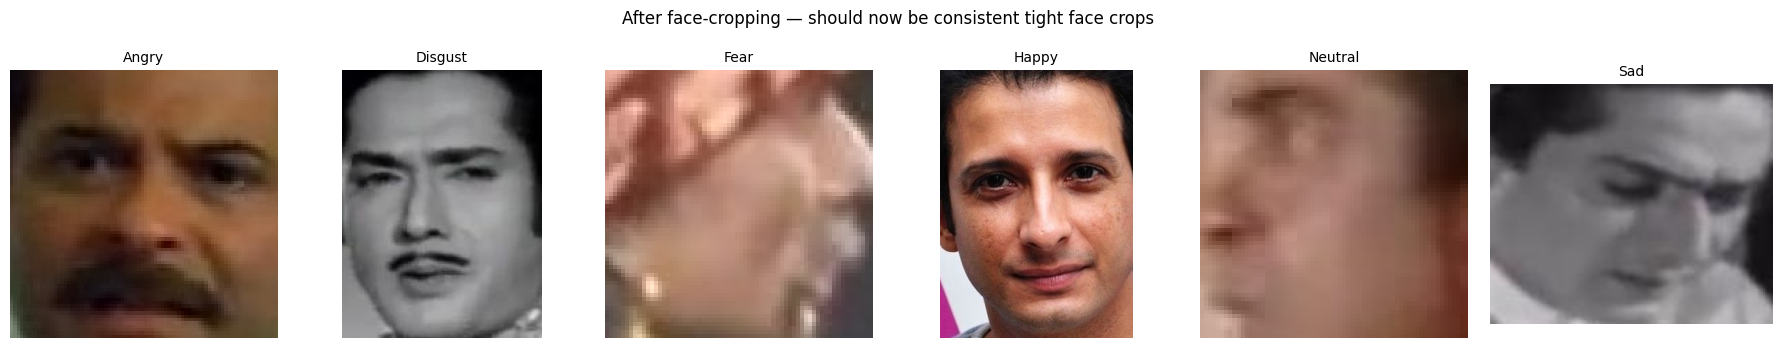

In [11]:
# Sanity check: view a few cropped results
n = min(7, len(os.listdir(dataset_root)))
sample_emotions = sorted(os.listdir(dataset_root))[:n]
fig, axes = plt.subplots(1, n, figsize=(3 * n, 3.5))
for ax, emotion in zip(axes if n > 1 else [axes], sample_emotions):
    folder = os.path.join(dataset_root, emotion)
    files = os.listdir(folder)
    if files:
        img = cv2.cvtColor(cv2.imread(os.path.join(folder, random.choice(files))), cv2.COLOR_BGR2RGB)
        ax.imshow(img)
    ax.set_title(emotion, fontsize=10)
    ax.axis('off')
plt.suptitle("After face-cropping — should now be consistent tight face crops", fontsize=12)
plt.tight_layout()
plt.show()

---
##  Section 2b — Remove Duplicate Images



In [12]:
import hashlib

seen_hashes = {}      # hash -> filepath (first occurrence kept)
removed_count = 0
removed_by_class = {}

for emotion in sorted(os.listdir(dataset_root)):
    class_dir = os.path.join(dataset_root, emotion)
    if not os.path.isdir(class_dir):
        continue
    for fname in list(os.listdir(class_dir)):
        fpath = os.path.join(class_dir, fname)
        with open(fpath, 'rb') as f:
            file_hash = hashlib.md5(f.read()).hexdigest()

        if file_hash in seen_hashes:
            os.remove(fpath)
            removed_count += 1
            removed_by_class[emotion] = removed_by_class.get(emotion, 0) + 1
        else:
            seen_hashes[file_hash] = fpath

print(f"✅ Deduplication complete. Removed {removed_count} duplicate image(s).")
if removed_by_class:
    print("\nDuplicates removed per class:")
    for emotion, n in sorted(removed_by_class.items()):
        print(f"  {emotion:>15s}: {n}")
print(f"\nRemaining unique images: {len(seen_hashes)}")

✅ Deduplication complete. Removed 268 duplicate image(s).

Duplicates removed per class:
            Angry: 46
          Disgust: 1
             Fear: 4
            Happy: 82
          Neutral: 87
              Sad: 48

Remaining unique images: 39634


---
##  Section 3 — Train / Validation / Test Split (70% / 15% / 15%)



In [13]:
import os, shutil
from sklearn.model_selection import train_test_split

# ── CONFIG ──────────────────────────────────────────────────────────────────
# If auto-detection above worked, dataset_root is already set.
# If not, manually set it: dataset_root = '/content/raw_dataset/YOUR_FOLDER'

OUTPUT_DIR   = '/content/data/'
VAL_SIZE     = 0.15   # 15% for validation
TEST_SIZE    = 0.15   # 15% for testing  (remaining 70% is training)
RANDOM_STATE = 42
# ─────────────────────────────────────────────────────────────────────────────

emotion_folders = [d for d in os.listdir(dataset_root)
                   if os.path.isdir(os.path.join(dataset_root, d))]

print(f"Splitting {len(emotion_folders)} emotion classes into train/val/test (70/15/15)...\n")
totals = {'train': 0, 'val': 0, 'test': 0}

for emotion in emotion_folders:
    src_folder = os.path.join(dataset_root, emotion)
    all_files  = [f for f in os.listdir(src_folder)
                  if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]

    if len(all_files) == 0:
        print(f"  ⚠️  {emotion}: no image files found, skipping.")
        continue

    # Stage 1: split off 70% train, 30% remaining
    train_files, remaining_files = train_test_split(
        all_files, test_size=(VAL_SIZE + TEST_SIZE), random_state=RANDOM_STATE
    )
    # Stage 2: split the remaining 30% evenly into val (15%) and test (15%)
    val_files, test_files = train_test_split(
        remaining_files, test_size=0.5, random_state=RANDOM_STATE
    )

    for split, file_list in [('train', train_files), ('val', val_files), ('test', test_files)]:
        dest = os.path.join(OUTPUT_DIR, split, emotion)
        os.makedirs(dest, exist_ok=True)
        for f in file_list:
            shutil.copy(os.path.join(src_folder, f), os.path.join(dest, f))

    print(f"  {emotion:>20s} → train: {len(train_files):4d}  |  val: {len(val_files):4d}  |  test: {len(test_files):4d}")
    totals['train'] += len(train_files)
    totals['val']   += len(val_files)
    totals['test']  += len(test_files)

print(f"\n✅ Split done! Total → train: {totals['train']}  |  val: {totals['val']}  |  test: {totals['test']}")
print(f"   Saved to: {OUTPUT_DIR}")

Splitting 6 emotion classes into train/val/test (70/15/15)...

                 Angry → train: 5239  |  val: 1123  |  test: 1123
                 Happy → train: 7501  |  val: 1608  |  test: 1608
                  Fear → train: 1066  |  val:  229  |  test:  229
               Disgust → train:  739  |  val:  158  |  test:  159
                   Sad → train: 3422  |  val:  733  |  test:  734
               Neutral → train: 9774  |  val: 2094  |  test: 2095

✅ Split done! Total → train: 27741  |  val: 5945  |  test: 5948
   Saved to: /content/data/


---
##  Section 3a — Offline Data Augmentation (Balance Train Set on Disk)



In [14]:
# ── OFFLINE DATA AUGMENTATION (train set only) ──────────────────────────────
# Unlike the real-time/online augmentation an ImageDataGenerator applies fresh
# each epoch, this generates augmented images ONCE and writes them to disk as
# real files inside each class's train folder. This physically balances class
# counts BEFORE training starts. class_weight is ALSO applied later during
# training (Section 7) as a belt-and-suspenders combo — it will end up close
# to uniform (~1.0 for every class) since the data is already balanced, but it
# still corrects for any small residual imbalance left after augmentation
# (e.g. from integer rounding when generating synthetic images).

import cv2
import numpy as np
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array, array_to_img

TRAIN_DIR    = '/content/data/train/'
TARGET_COUNT = None   # None = balance every class up to match the largest class

offline_aug = ImageDataGenerator(
    rotation_range=15,
    zoom_range=0.15,
    width_shift_range=0.10,
    height_shift_range=0.10,
    shear_range=0.10,
    brightness_range=[0.85, 1.15],
    horizontal_flip=True,
    fill_mode='nearest'
)

class_dirs = {e: os.path.join(TRAIN_DIR, e) for e in sorted(os.listdir(TRAIN_DIR))}
class_counts = {e: len([f for f in os.listdir(d) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))])
                for e, d in class_dirs.items()}

target = TARGET_COUNT or max(class_counts.values())
print(f"Target images per class: {target}\n")

for emotion, folder in class_dirs.items():
    files = [f for f in os.listdir(folder) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]
    current_count = len(files)
    needed = target - current_count

    if needed <= 0:
        print(f"  {emotion:>20s}: {current_count} images — already at/above target, skipping.")
        continue

    print(f"  {emotion:>20s}: {current_count} → generating {needed} augmented images...")
    generated = 0
    file_idx  = 0
    while generated < needed:
        fname = files[file_idx % len(files)]
        img = cv2.imread(os.path.join(folder, fname))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        x = img_to_array(img)
        x = np.expand_dims(x, axis=0)

        aug_iter = offline_aug.flow(x, batch_size=1, seed=42 + generated)
        aug_img  = next(aug_iter)[0].astype('uint8')

        save_name = f"aug_{generated:05d}_{fname}"
        array_to_img(aug_img).save(os.path.join(folder, save_name))

        generated += 1
        file_idx  += 1

print("\n✅ Offline augmentation complete — train classes balanced on disk.")

class_counts_after = {e: len([f for f in os.listdir(d) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))])
                       for e, d in class_dirs.items()}
print("\nUpdated train counts:")
for e, c in class_counts_after.items():
    print(f"  {e:>20s}: {c}")


Target images per class: 9774

                 Angry: 5239 → generating 4535 augmented images...
               Disgust: 739 → generating 9035 augmented images...
                  Fear: 1066 → generating 8708 augmented images...
                 Happy: 7501 → generating 2273 augmented images...
               Neutral: 9774 images — already at/above target, skipping.
                   Sad: 3422 → generating 6352 augmented images...

✅ Offline augmentation complete — train classes balanced on disk.

Updated train counts:
                 Angry: 9774
               Disgust: 9774
                  Fear: 9774
                 Happy: 9774
               Neutral: 9774
                   Sad: 9774


---
##  Section 4 — Data Exploration & Class Imbalance Analysis

Emotion classes: ['Angry', 'Disgust', 'Fear', 'Happy', 'Neutral', 'Sad']


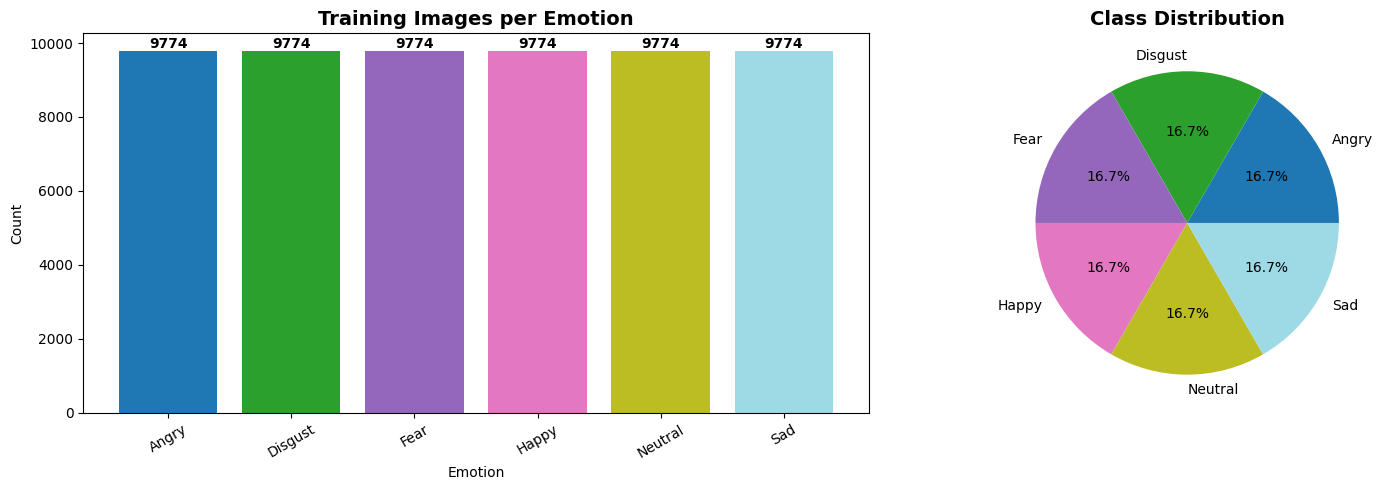

In [15]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np
import os

train_dir = '/content/data/train/'
emotions  = sorted(os.listdir(train_dir))
print("Emotion classes:", emotions)

# Count images per class
counts = {e: len(os.listdir(os.path.join(train_dir, e))) for e in emotions}
palette = [cm.tab20(i / max(len(emotions) - 1, 1)) for i in range(len(emotions))]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

bars = axes[0].bar(counts.keys(), counts.values(), color=palette)
axes[0].set_title('Training Images per Emotion', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Emotion')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=30)
for bar, count in zip(bars, counts.values()):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                 str(count), ha='center', va='bottom', fontweight='bold')

axes[1].pie(counts.values(), labels=counts.keys(), autopct='%1.1f%%', colors=palette)
axes[1].set_title('Class Distribution', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

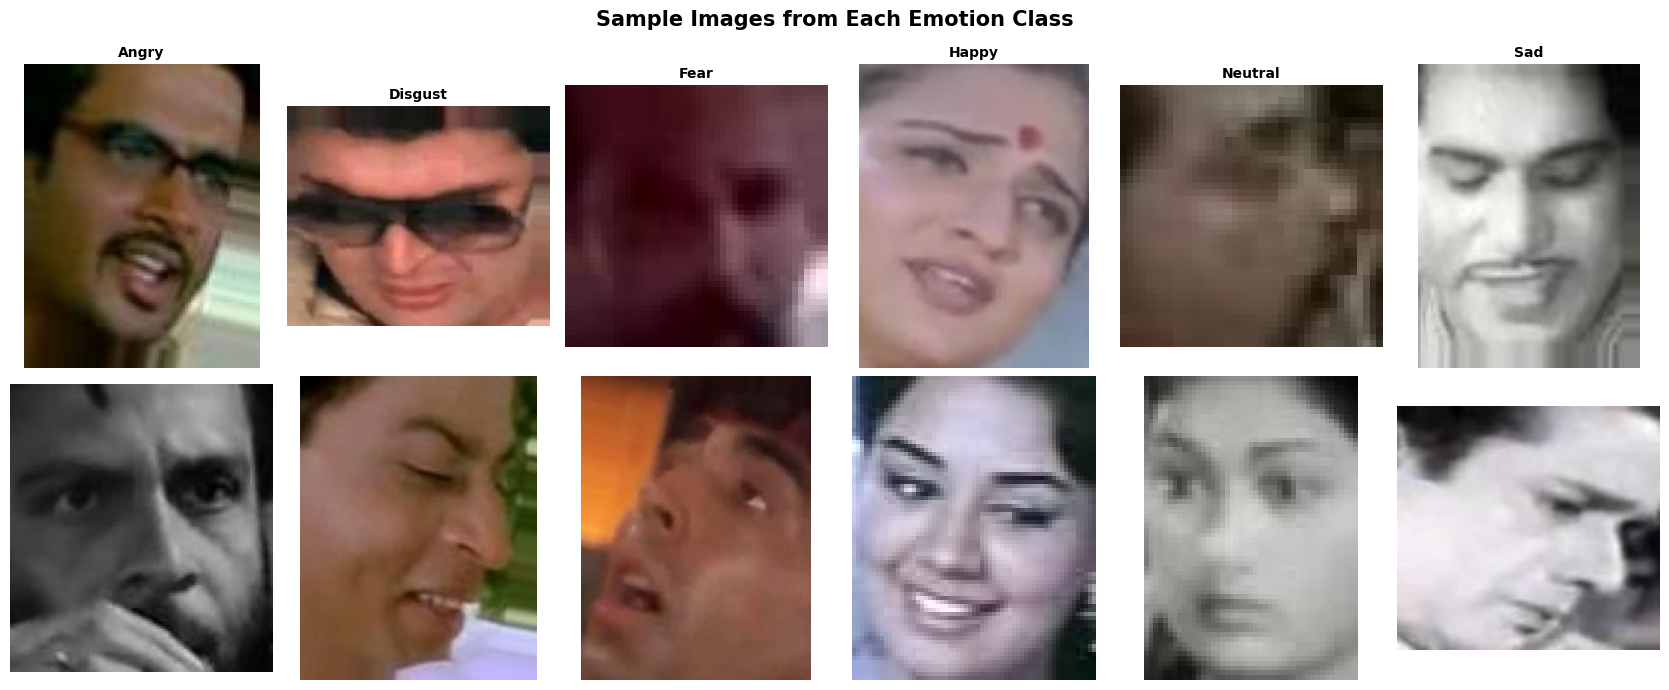

In [16]:
# Show sample images from each emotion
import cv2

n_cols = len(emotions)
fig, axes = plt.subplots(2, n_cols, figsize=(2.8 * n_cols, 7))
fig.suptitle('Sample Images from Each Emotion Class', fontsize=15, fontweight='bold')

for col, emotion in enumerate(emotions):
    folder = os.path.join(train_dir, emotion)
    imgs   = os.listdir(folder)
    for row in range(2):
        ax = axes[row, col] if n_cols > 1 else axes[row]
        if row < len(imgs):
            img_path = os.path.join(folder, imgs[row])
            img = cv2.imread(img_path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            ax.imshow(img)
        ax.axis('off')
        if row == 0:
            ax.set_title(emotion, fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

In [17]:
# ── Class Imbalance Analysis ─────────────────────────────────────────────
counts_arr = np.array(list(counts.values()))
max_count, min_count = counts_arr.max(), counts_arr.min()
imbalance_ratio = max_count / min_count

print("=" * 55)
print(" DATASET STATISTICS")
print("=" * 55)
print(f"Total classes        : {len(emotions)}")
print(f"Total training images: {counts_arr.sum()}")
print(f"Mean images/class    : {counts_arr.mean():.1f}")
print(f"Std dev              : {counts_arr.std():.1f}")
print(f"Largest class        : {max(counts, key=counts.get)} ({max_count})")
print(f"Smallest class       : {min(counts, key=counts.get)} ({min_count})")
print(f"Imbalance ratio       : {imbalance_ratio:.1f}x (largest ÷ smallest)")
print()

if imbalance_ratio > 3:
    print(f"⚠️  Dataset is IMBALANCED (ratio {imbalance_ratio:.1f}x exceeds the common 3x threshold).")
else:
    print(f"✅ Dataset is roughly balanced (ratio {imbalance_ratio:.1f}x).")

 DATASET STATISTICS
Total classes        : 6
Total training images: 58644
Mean images/class    : 9774.0
Std dev              : 0.0
Largest class        : Angry (9774)
Smallest class       : Angry (9774)
Imbalance ratio       : 1.0x (largest ÷ smallest)

✅ Dataset is roughly balanced (ratio 1.0x).


---
##  Section 5 — Data Leakage Verification



In [18]:
import hashlib

def hash_all_images(root_dir):
    """Return {md5_hash: filepath} for every image under root_dir."""
    hashes = {}
    for dirpath, _, filenames in os.walk(root_dir):
        for fname in filenames:
            fpath = os.path.join(dirpath, fname)
            with open(fpath, 'rb') as f:
                file_hash = hashlib.md5(f.read()).hexdigest()
            hashes[file_hash] = fpath
    return hashes

train_hashes = hash_all_images('/content/data/train/')
val_hashes   = hash_all_images('/content/data/val/')
test_hashes  = hash_all_images('/content/data/test/')

train_val_overlap  = set(train_hashes) & set(val_hashes)
train_test_overlap = set(train_hashes) & set(test_hashes)
val_test_overlap    = set(val_hashes) & set(test_hashes)

total_overlap = train_val_overlap | train_test_overlap | val_test_overlap

print(f"Train images: {len(train_hashes)}  |  Val images: {len(val_hashes)}  |  Test images: {len(test_hashes)}")
print(f"Train↔Val duplicate images : {len(train_val_overlap)}")
print(f"Train↔Test duplicate images: {len(train_test_overlap)}")
print(f"Val↔Test duplicate images  : {len(val_test_overlap)}")
print()

if len(total_overlap) == 0:
    print("✅ No Data Leakage Detected")
else:
    print(f"⚠️  WARNING: {len(total_overlap)} duplicate image(s) found across splits!")
    for h in list(total_overlap)[:10]:
        print(f"   {train_hashes.get(h) or val_hashes.get(h)}  ↔  duplicate hash {h[:10]}...")

Train images: 58644  |  Val images: 5945  |  Test images: 5948
Train↔Val duplicate images : 0
Train↔Test duplicate images: 0
Val↔Test duplicate images  : 0

✅ No Data Leakage Detected


---
## Section 6 — Build Custom Residual CNN (Version 3)



In [19]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.layers import (
    Input, Conv2D, BatchNormalization, Activation,
    MaxPooling2D, GlobalAveragePooling2D,
    SpatialDropout2D, Dropout, Dense, Add
)
from keras.regularizers import l2
from keras.initializers import he_normal
from keras.models import Model
from keras.optimizers import Adam
from keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau, CSVLogger
import os

# ── PATHS & LABELS ───────────────────────────────────────────────────────────
train_data_dir = '/content/data/train/'
val_data_dir   = '/content/data/val/'
test_data_dir  = '/content/data/test/'

class_labels = sorted(os.listdir(train_data_dir))
NUM_CLASSES  = len(class_labels)
print(f'Classes ({NUM_CLASSES}):', class_labels)

# ── DATA AUGMENTATION (training set only) ────────────────────────────────────
# ANTI-OVERFITTING FIX: previously train_datagen only rescaled, so every epoch
# saw the exact same static offline-augmented files, encouraging memorization
# (train 93.40% vs val 68.05%, 25-point gap). Adding light ONLINE augmentation
# on top means each epoch now sees a fresh random variation of every image —
# ranges kept small since the offline step already diversified the dataset once;
# stacking two aggressive augmentations would distort faces too much at 48×48.
# vertical_flip intentionally NOT used — upside-down faces never occur in deployment.
# seed=42 kept for reproducibility.
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=8,
    zoom_range=0.08,
    width_shift_range=0.06,
    height_shift_range=0.06,
    horizontal_flip=True,
    fill_mode='nearest'
)
val_datagen  = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_data_dir,
    color_mode='grayscale',
    target_size=(48, 48),
    batch_size=32,
    class_mode='categorical',
    shuffle=True,
    seed=42
)
val_generator = val_datagen.flow_from_directory(
    val_data_dir,
    color_mode='grayscale',
    target_size=(48, 48),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)
test_generator = test_datagen.flow_from_directory(
    test_data_dir,
    color_mode='grayscale',
    target_size=(48, 48),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

labels_dict = {v: k for k, v in train_generator.class_indices.items()}
print('Label mapping:', labels_dict)

Classes (6): ['Angry', 'Disgust', 'Fear', 'Happy', 'Neutral', 'Sad']
Found 58644 images belonging to 6 classes.
Found 5945 images belonging to 6 classes.
Found 5948 images belonging to 6 classes.
Label mapping: {0: 'Angry', 1: 'Disgust', 2: 'Fear', 3: 'Happy', 4: 'Neutral', 5: 'Sad'}


In [20]:
# ── Custom Residual CNN — Version 3 ──────────────────────────────────────────
# Built entirely from scratch. No pretrained weights, no transfer learning.
# Uses Keras Functional API (not Sequential) to support skip connections.

def residual_block(x, filters, spatial_dr=0.20, l2_rate=1.5e-4):
    """
    Dual-conv residual block with pre-activation BatchNorm:
      Conv(3×3)+BN+ReLU → Conv(3×3)+BN → Add(skip) → ReLU → MaxPool → SpatialDropout2D

    Why dual conv:
      First Conv detects simple patterns (edges). Second Conv combines them
      into higher-order patterns (shape parts) BEFORE MaxPool discards resolution.
      Single conv (v2) left this second stage missing, capping accuracy at 63%.

    Why skip connection:
      Adds the block input directly to the block output. Gradients flow directly
      to every block from the loss — early blocks keep learning in all epochs
      instead of saturating after ~epoch 20 as in v2.

    Why SpatialDropout2D:
      Drops entire feature map channels rather than individual values.
      Forces remaining channels to carry independent information.
      Far more effective than Dropout(0.1) on feature maps.

    Why padding='same':
      v2 used padding='valid' causing 48→46→44 shrinkage before first pool.
      padding='same' preserves spatial dimensions at zero parameter cost.

    Why He initialisation:
      Mathematically correct for ReLU activations. Glorot (default) under-scales
      variance for ReLU, causing early saturation in deep networks.
    """
    init     = he_normal(seed=42)
    shortcut = x

    # First conv
    x = Conv2D(filters, (3,3), padding='same', use_bias=False,
               kernel_initializer=init, kernel_regularizer=l2(l2_rate))(x)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)

    # Second conv
    x = Conv2D(filters, (3,3), padding='same', use_bias=False,
               kernel_initializer=init, kernel_regularizer=l2(l2_rate))(x)
    x = BatchNormalization()(x)

    # 1×1 projection if channel count changed (minimal params)
    if shortcut.shape[-1] != filters:
        shortcut = Conv2D(filters, (1,1), padding='same', use_bias=False,
                          kernel_initializer=init,
                          kernel_regularizer=l2(l2_rate))(shortcut)
        shortcut = BatchNormalization()(shortcut)

    x = Add()([x, shortcut])   # residual addition
    x = Activation('relu')(x)  # ReLU after addition
    x = MaxPooling2D((2,2))(x)
    x = SpatialDropout2D(spatial_dr)(x)
    return x


def build_residual_cnn(num_classes, input_shape=(48, 48, 1)):
    inputs = Input(shape=input_shape, name='input_image')

    x = residual_block(inputs, 32)   # 48×48 → 24×24
    x = residual_block(x,     64)   # 24×24 → 12×12
    x = residual_block(x,    128)   # 12×12 →  6×6
    x = residual_block(x,    256)   #  6×6  →  3×3

    # GlobalAveragePooling: collapses each of 256 maps to 1 value → 256-dim vector.
    # Avoids the parameter explosion of Flatten (3×3×256=2304 → dense: +885K params).
    x = GlobalAveragePooling2D(name='gap')(x)

    # Classifier head: 256 → 256
    # BALANCE FIX: the previous pass (Dropout 0.50, L2 3e-4, spatial_dr 0.25)
    # over-corrected — train accuracy fell to 75.5% (underfitting), even though
    # val gap was healthy (7.17 pts). Loosening Dropout 0.50→0.40 and L2
    # 3e-4→1.5e-4 (spatial_dr 0.25→0.20 in residual blocks) gives the model back
    # some learning capacity so train accuracy can rise, while online
    # augmentation + moderate regularisation should still keep the val gap small.
    x = Dense(256, use_bias=False,
              kernel_initializer=he_normal(seed=42),
              kernel_regularizer=l2(1.5e-4),
              name='dense_256')(x)
    x = BatchNormalization(name='bn_head')(x)
    x = Activation('relu', name='relu_head')(x)
    x = Dropout(0.40, name='dropout_head')(x)

    outputs = Dense(num_classes, activation='softmax',
                    kernel_initializer=he_normal(seed=42),
                    dtype='float32',
                    name='predictions')(x)

    return Model(inputs, outputs, name='CustomResidualCNN_v3')


model = build_residual_cnn(NUM_CLASSES)
model.compile(
    optimizer=Adam(learning_rate=5e-4),   # explicit 5e-4: more stable than default 1e-3
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
model.summary()

Model: "CustomResidualCNN_v3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 48, 48, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 48, 48,    │        288 │ input_image[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 48, 48,    │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 48, 48,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 48, 48,    │      9,216 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 48, 48,    │         32 │ input_image[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 48, 48,    │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 48, 48,    │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 48, 48,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 48, 48,    │          0 │ add[0][0]         │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 24, 24,    │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout2d   │ (None, 24, 24,    │          0 │ max_pooling2d[0]… │
│ (SpatialDropout2D)  │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 24, 24,    │     18,432 │ spatial_dropout2… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 24, 24,    │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 24, 24,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 24, 24,    │     36,864 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 24, 24,    │      2,048 │ spatial_dropout2

 Total params: 1,287,622 (4.91 MB)

 Trainable params: 1,284,230 (4.90 MB)

 Non-trainable params: 3,392 (13.25 KB)

---
##  Section 7 — Train the Model

In [21]:
# len(generator) is always exact — manual num_imgs // 32 truncates last partial batch
STEPS_PER_EPOCH  = len(train_generator)
VALIDATION_STEPS = len(val_generator)

print(f'Training images  : {sum(len(f) for _,_,f in os.walk(train_data_dir))}')
print(f'Validation images: {sum(len(f) for _,_,f in os.walk(val_data_dir))}')
print(f'Steps per epoch  : {STEPS_PER_EPOCH}')
print(f'Validation steps : {VALIDATION_STEPS}')

checkpoint = ModelCheckpoint(
    'emotion_model_best.keras',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=18,              # BALANCE FIX: raised 12→18 — the model was
                              # underfitting (train 75.5%), so give it more
                              # epochs of room before stopping to let train
                              # accuracy climb further.
    restore_best_weights=True,
    verbose=1
)
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=6,               # BALANCE FIX: raised 4→6 — matches the longer
                              # early-stopping patience so LR isn't cut too
                              # aggressively before the model has had time to
                              # improve.
    min_lr=1e-7,
    verbose=1
)
csv_logger = CSVLogger('training_log.csv', append=False)

print('\n✅ Callbacks ready: ModelCheckpoint + EarlyStopping(p=18) + ReduceLROnPlateau + CSVLogger')

Training images  : 58644
Validation images: 5945
Steps per epoch  : 1833
Validation steps : 186

✅ Callbacks ready: ModelCheckpoint + EarlyStopping(p=18) + ReduceLROnPlateau + CSVLogger


In [22]:
# ── Class Weights (extra safety net on top of offline augmentation) ─────────
# The train set was already balanced on disk in Section 3a, so these weights
# should come out close to uniform (~1.0 each). We still compute + apply them
# in case augmentation left small residual imbalance (e.g. rounding when
# target counts don't divide evenly), and to make it easy to disable offline
# augmentation later without losing imbalance protection.
from sklearn.utils.class_weight import compute_class_weight

y_train_labels = train_generator.classes
class_weight_values = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_labels),
    y=y_train_labels
)

# Cap the maximum weight (relative to the smallest weight) to avoid over-correction.
# With the train set already balanced by offline augmentation, capping matters less
# here than in the class-weight-only variant, but it's kept as a safety net in case
# any class still has meaningfully fewer images after augmentation.
MAX_WEIGHT_RATIO = 5.0
min_weight = class_weight_values.min()
capped_weights = np.minimum(class_weight_values, min_weight * MAX_WEIGHT_RATIO)

class_weight_dict = {i: w for i, w in enumerate(capped_weights)}

print("Class weights (higher = rarer class, penalized more during training):")
print(f"(capped at {MAX_WEIGHT_RATIO}x the smallest class's weight)\n")
for idx, (raw, capped) in enumerate(zip(class_weight_values, capped_weights)):
    marker = "  ← capped" if raw > capped else ""
    print(f"  {labels_dict[idx]:>15s}: raw={raw:.3f}  used={capped:.3f}{marker}")


Class weights (higher = rarer class, penalized more during training):
(capped at 5.0x the smallest class's weight)

            Angry: raw=1.000  used=1.000
          Disgust: raw=1.000  used=1.000
             Fear: raw=1.000  used=1.000
            Happy: raw=1.000  used=1.000
          Neutral: raw=1.000  used=1.000
              Sad: raw=1.000  used=1.000


In [23]:
# EPOCHS raised 50→100: residual CNN with LR=5e-4 converges slower but peaks higher.
# EarlyStopping (patience=20) will cut training automatically if val_loss plateaus.
EPOCHS = 100

history = model.fit(
    train_generator,
    steps_per_epoch=STEPS_PER_EPOCH,
    epochs=EPOCHS,
    validation_data=val_generator,
    validation_steps=VALIDATION_STEPS,
    class_weight=class_weight_dict,
    callbacks=[checkpoint, early_stop, reduce_lr, csv_logger]
)

print('\n✅ Best model (highest val_accuracy) saved as emotion_model_best.keras')

Epoch 1/100
1833/1833 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.2220 - loss: 2.4475
Epoch 1: val_accuracy improved from None to 0.33373, saving model to emotion_model_best.keras

Epoch 1: finished saving model to emotion_model_best.keras
1833/1833 ━━━━━━━━━━━━━━━━━━━━ 117s 53ms/step - accuracy: 0.2375 - loss: 2.3172 - val_accuracy: 0.3337 - val_loss: 2.0440 - learning_rate: 5.0000e-04
Epoch 2/100
1833/1833 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.2897 - loss: 2.0720
Epoch 2: val_accuracy improved from 0.33373 to 0.42372, saving model to emotion_model_best.keras

Epoch 2: finished saving model to emotion_model_best.keras
1833/1833 ━━━━━━━━━━━━━━━━━━━━ 82s 45ms/step - accuracy: 0.3145 - loss: 1.9980 - val_accuracy: 0.4237 - val_loss: 1.7658 - learning_rate: 5.0000e-04
Epoch 3/100
1832/1833 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.4019 - loss: 1.7701
Epoch 3: val_accuracy improved from 0.42372 to 0.54500, saving model to emotion_model_best.keras

Epoch 3: finished savi

---
##  Section 8 — Evaluate Model

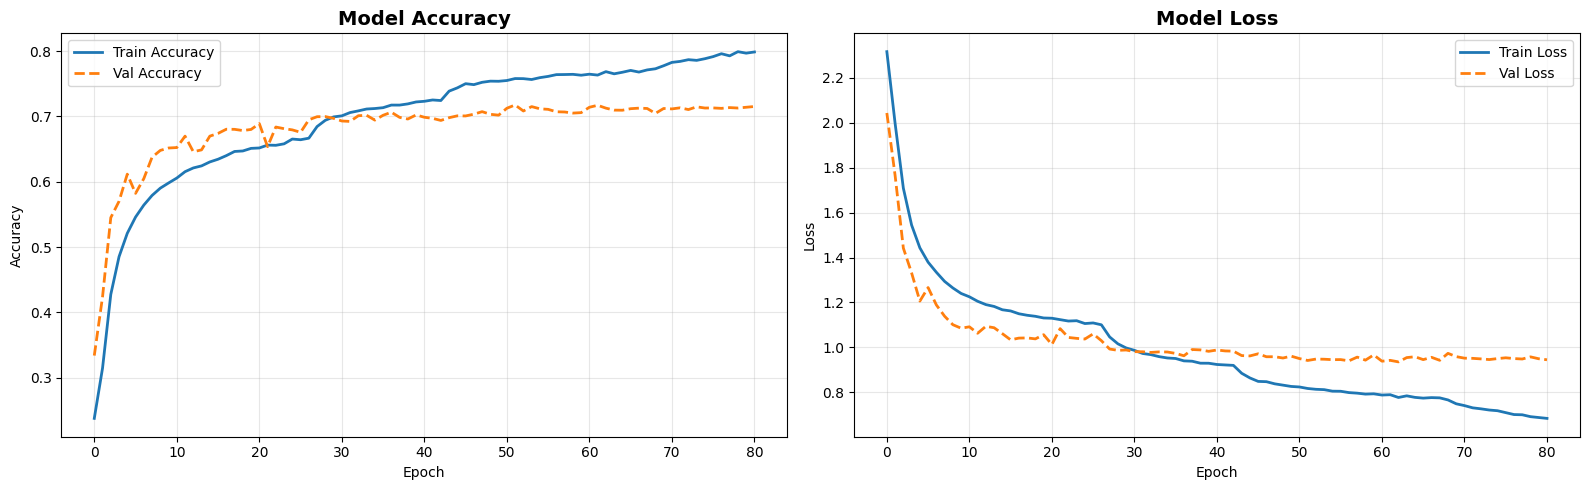

Plot saved as training_history.png


In [24]:
# Plot training history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

ax1.plot(history.history['accuracy'],     label='Train Accuracy', linewidth=2)
ax1.plot(history.history['val_accuracy'], label='Val Accuracy',   linewidth=2, linestyle='--')
ax1.set_title('Model Accuracy', fontsize=14, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(history.history['loss'],     label='Train Loss', linewidth=2)
ax2.plot(history.history['val_loss'], label='Val Loss',   linewidth=2, linestyle='--')
ax2.set_title('Model Loss', fontsize=14, fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('training_history.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved as training_history.png")

186/186 ━━━━━━━━━━━━━━━━━━━━ 7s 30ms/step

✅ Final Test Accuracy: 70.93%

              precision    recall  f1-score   support

       Angry       0.72      0.67      0.69      1123
     Disgust       0.45      0.37      0.41       159
        Fear       0.59      0.52      0.55       229
       Happy       0.79      0.73      0.76      1608
     Neutral       0.71      0.79      0.75      2095
         Sad       0.60      0.64      0.62       734

    accuracy                           0.71      5948
   macro avg       0.64      0.62      0.63      5948
weighted avg       0.71      0.71      0.71      5948



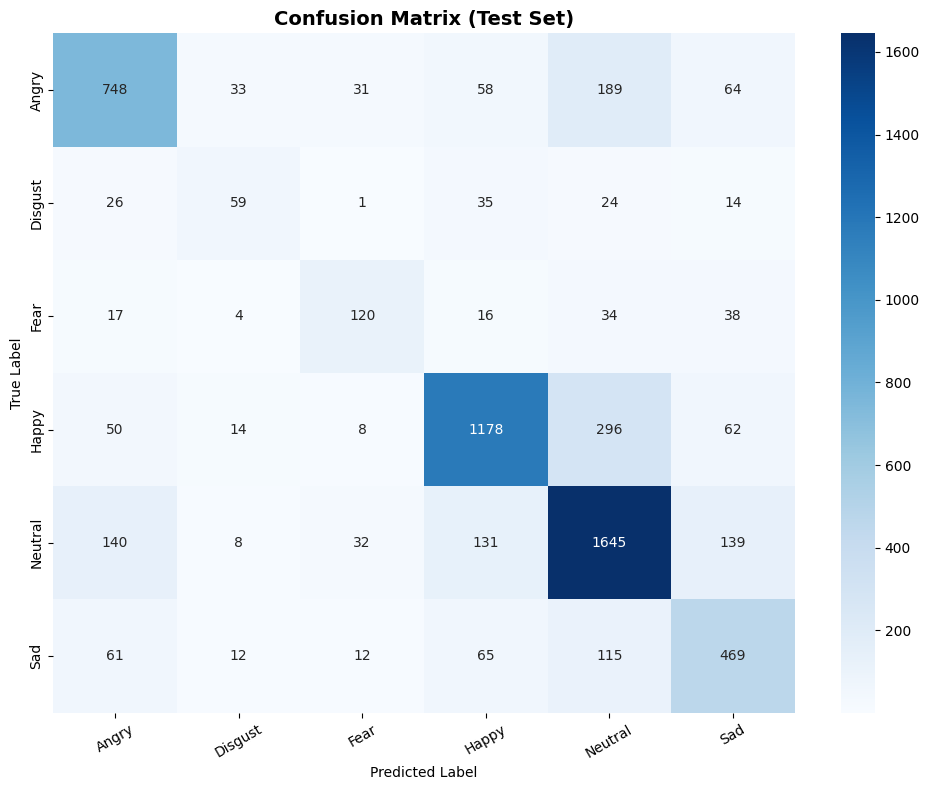

Saved as confusion_matrix.png


In [25]:
# Confusion matrix & classification report — evaluated on the held-out TEST set
# (never seen during training or callback-driven tuning decisions)
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
from keras.models import load_model

best_model = load_model('emotion_model_best.keras')

test_generator.reset()
y_pred  = best_model.predict(test_generator, verbose=1)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true  = test_generator.classes
class_names = list(labels_dict.values())

test_accuracy = np.mean(y_pred_classes == y_true)
print(f"\n✅ Final Test Accuracy: {test_accuracy*100:.2f}%\n")

print(classification_report(y_true, y_pred_classes, target_names=class_names))

cm = confusion_matrix(y_true, y_pred_classes)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix (Test Set)', fontsize=14, fontweight='bold')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved as confusion_matrix.png")

---
##  Section 9 — Overfitting / Underfitting Analysis

In [26]:
final_train_acc  = history.history['accuracy'][-1]
final_val_acc    = history.history['val_accuracy'][-1]
final_train_loss = history.history['loss'][-1]
final_val_loss   = history.history['val_loss'][-1]

acc_gap  = final_train_acc - final_val_acc
loss_gap = final_val_loss - final_train_loss

print("=" * 55)
print(" FINAL EPOCH METRICS")
print("=" * 55)
print(f"Training Accuracy   : {final_train_acc*100:.2f}%")
print(f"Validation Accuracy : {final_val_acc*100:.2f}%")
print(f"Training Loss       : {final_train_loss:.4f}")
print(f"Validation Loss     : {final_val_loss:.4f}")
print(f"Accuracy Gap (train-val): {acc_gap*100:.2f} points")
print(f"Loss Gap (val-train)    : {loss_gap:.4f}")
print()

if final_train_acc < 0.6 and final_val_acc < 0.6:
    print("📉 Diagnosis: UNDERFITTING")
    print("   Both training and validation accuracy are low — the model hasn't learned the")
    print("   patterns well enough yet.")
    print("   Recommendations: train for more epochs, reduce Dropout/L2 slightly, or add model capacity.")
elif acc_gap > 0.15 or loss_gap > 0.3:
    print("📈 Diagnosis: OVERFITTING")
    print("   Training accuracy is notably higher than validation accuracy — the model is")
    print("   memorizing training-specific patterns rather than generalizing.")
    print("   Recommendations: increase Dropout, add more augmentation, or gather more data")
    print("   for underrepresented classes.")
else:
    print("✅ Diagnosis: WELL GENERALIZED")
    print("   Training and validation accuracy/loss are close together, indicating the model")
    print("   generalizes reasonably well to unseen data.")

 FINAL EPOCH METRICS
Training Accuracy   : 79.87%
Validation Accuracy : 71.52%
Training Loss       : 0.6832
Validation Loss     : 0.9444
Accuracy Gap (train-val): 8.35 points
Loss Gap (val-train)    : 0.2612

✅ Diagnosis: WELL GENERALIZED
   Training and validation accuracy/loss are close together, indicating the model
   generalizes reasonably well to unseen data.


---
##  Section 10 — Final Comprehensive Analysis Report



In [27]:
print("=" * 60)
print(" FINAL COMPREHENSIVE ANALYSIS REPORT")
print("=" * 60)

# 1. Data Leakage ------------------------------------------------------------
print("\n1) DATA LEAKAGE")
if len(total_overlap) == 0:
    print("   ✅ No Data Leakage Detected — 0 duplicate images across train/val/test.")
else:
    print(f"   ⚠️  {len(total_overlap)} duplicate image(s) still found across splits.")

# 2. Class Imbalance ----------------------------------------------------------
print("\n2) CLASS IMBALANCE")
print(f"   Largest class : {max(counts, key=counts.get)} ({max_count} images)")
print(f"   Smallest class: {min(counts, key=counts.get)} ({min_count} images)")
print(f"   Imbalance ratio: {imbalance_ratio:.1f}x")
if imbalance_ratio > 3:
    print("   ⚠️  Imbalanced dataset — mitigated via class weights + augmentation (not sampling).")
else:
    print("   ✅ Roughly balanced dataset.")

# 3. Bias ----------------------------------------------------------------------
print("\n3) BIAS")
print("   Dataset bias: model reflects the lighting/pose/camera conditions of the source dataset.")
print("   Prediction bias risk: partially mitigated via class weights (see Section 4 Bias Analysis")
print("   for full discussion) — verify with per-class precision/recall in Section 8, not just")
print("   overall accuracy.")

# 4. Overfitting / Underfitting ------------------------------------------------
print("\n4) MODEL FIT")
print(f"   Training Accuracy  : {final_train_acc*100:.2f}%")
print(f"   Validation Accuracy: {final_val_acc*100:.2f}%")
print(f"   Test Accuracy      : {test_accuracy*100:.2f}%")
if final_train_acc < 0.6 and final_val_acc < 0.6:
    fit_diagnosis = "UNDERFITTING"
elif acc_gap > 0.15 or loss_gap > 0.3:
    fit_diagnosis = "OVERFITTING"
else:
    fit_diagnosis = "WELL GENERALIZED"
print(f"   Diagnosis: {fit_diagnosis}")

# 5. Overall Generalization Verdict -------------------------------------------
print("\n5) OVERALL MODEL GENERALIZATION")
gap_test_val = abs(test_accuracy - final_val_acc)
if gap_test_val < 0.05 and fit_diagnosis == "WELL GENERALIZED":
    print("   ✅ Test accuracy is consistent with validation accuracy — the model generalizes")
    print("      reliably to unseen data.")
elif fit_diagnosis == "UNDERFITTING":
    print("   ⚠️  Model has not yet reached its potential — see Section 9 recommendations")
    print("      (more epochs, lighter regularization, more capacity) before treating this")
    print("      as a final result.")
else:
    print(f"   ℹ️  Test vs. validation accuracy gap: {gap_test_val*100:.2f} points — review Section 9")
    print("      for the full overfitting/underfitting discussion.")
print("\n" + "=" * 60)

 FINAL COMPREHENSIVE ANALYSIS REPORT

1) DATA LEAKAGE
   ✅ No Data Leakage Detected — 0 duplicate images across train/val/test.

2) CLASS IMBALANCE
   Largest class : Angry (9774 images)
   Smallest class: Angry (9774 images)
   Imbalance ratio: 1.0x
   ✅ Roughly balanced dataset.

3) BIAS
   Dataset bias: model reflects the lighting/pose/camera conditions of the source dataset.
   Prediction bias risk: partially mitigated via class weights (see Section 4 Bias Analysis
   for full discussion) — verify with per-class precision/recall in Section 8, not just
   overall accuracy.

4) MODEL FIT
   Training Accuracy  : 79.87%
   Validation Accuracy: 71.52%
   Test Accuracy      : 70.93%
   Diagnosis: WELL GENERALIZED

5) OVERALL MODEL GENERALIZATION
   ✅ Test accuracy is consistent with validation accuracy — the model generalizes
      reliably to unseen data.



---
## Section 11 — Save & Download Final Model

In [28]:
# Save the final model in the modern Keras format (as required for VS Code deployment)
model.save('emotion_model.keras')
print("✅ Final model saved as emotion_model.keras")

✅ Final model saved as emotion_model.keras


In [29]:
# Option A: Download model + evaluation artifacts directly to your computer
from google.colab import files
files.download('emotion_model.keras')
files.download('training_history.png')
files.download('confusion_matrix.png')
files.download('class_distribution.png')
print("✅ Files downloaded!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Files downloaded!


In [30]:
# Option B: Save model + artifacts to Google Drive
import shutil
drive_save_path = '/content/drive/MyDrive/EmotionModel/'  # change folder name if needed
os.makedirs(drive_save_path, exist_ok=True)

for fname in ['emotion_model.keras', 'training_history.png', 'confusion_matrix.png', 'class_distribution.png']:
    shutil.copy(fname, drive_save_path)

print(f"✅ All files saved to Google Drive at: {drive_save_path}")

✅ All files saved to Google Drive at: /content/drive/MyDrive/EmotionModel/


---
## Section 10 — Smoke Test

A **smoke test** is not an accuracy check — it's a fast sanity check that the
saved model actually works end-to-end the way a real deployment would use it:
load the saved `.keras` file fresh (no leftover training-session state),
run it on a handful of real images, and confirm nothing crashes, output
shapes are correct, probabilities are valid, and inference is fast enough
to be usable. If this fails, something is broken even if training metrics
looked fine.


In [31]:
# ── SMOKE TEST ────────────────────────────────────────────────────────────
# Does NOT change the model, architecture, or training pipeline in any way.
# Just verifies the saved artifact loads and behaves correctly before you
# trust it for deployment / your capstone demo.

import time
import numpy as np
from keras.models import load_model

SMOKE_TEST_SAMPLES = 10
all_checks_passed = True

print("=" * 60)
print("SMOKE TEST")
print("=" * 60)

# 1) Fresh load of the saved model (simulates real deployment, not the
#    in-memory `model`/`best_model` object still sitting in this session)
try:
    smoke_model = load_model('emotion_model.keras')
    print("✅ Model file loads without error")
except Exception as e:
    all_checks_passed = False
    print(f"❌ Model failed to load: {e}")

# 2) Pull a small random sample of real test images through the SAME
#    preprocessing the rest of the notebook uses (test_generator)
test_generator.reset()
sample_batch_x, sample_batch_y = next(iter(test_generator))
n = min(SMOKE_TEST_SAMPLES, sample_batch_x.shape[0])
sample_x = sample_batch_x[:n]
sample_y = sample_batch_y[:n]

# 3) Run predictions and time them
try:
    start = time.time()
    preds = smoke_model.predict(sample_x, verbose=0)
    elapsed = time.time() - start
    avg_ms = (elapsed / n) * 1000
    print(f"✅ Prediction ran without error on {n} sample images")
    print(f"   Avg inference time: {avg_ms:.1f} ms/image")
except Exception as e:
    all_checks_passed = False
    preds = None
    print(f"❌ Prediction failed: {e}")

if preds is not None:
    # 4) Output shape check — must be (n, NUM_CLASSES)
    expected_shape = (n, NUM_CLASSES)
    if preds.shape == expected_shape:
        print(f"✅ Output shape correct: {preds.shape}")
    else:
        all_checks_passed = False
        print(f"❌ Output shape wrong: got {preds.shape}, expected {expected_shape}")

    # 5) Probabilities must sum to ~1 per image (valid softmax output)
    row_sums = preds.sum(axis=1)
    if np.allclose(row_sums, 1.0, atol=1e-3):
        print(f"✅ Softmax outputs sum to ~1.0 (min={row_sums.min():.4f}, max={row_sums.max():.4f})")
    else:
        all_checks_passed = False
        print(f"❌ Softmax outputs don't sum to 1 — min={row_sums.min():.4f}, max={row_sums.max():.4f}")

    # 6) No NaN / Inf in outputs
    if np.isfinite(preds).all():
        print("✅ No NaN/Inf values in predictions")
    else:
        all_checks_passed = False
        print("❌ Found NaN/Inf in predictions — model is unstable")

    # 7) Predictions aren't collapsed onto a single class (a common silent
    #    failure mode — model technically 'works' but always predicts Neutral)
    pred_classes = np.argmax(preds, axis=1)
    unique_preds = len(np.unique(pred_classes))
    if unique_preds > 1:
        print(f"✅ Predictions span {unique_preds} different classes (not collapsed)")
    else:
        all_checks_passed = False
        print(f"⚠️  All {n} predictions collapsed onto a single class — investigate")

    # 8) Quick eyeball accuracy on this tiny sample (NOT a real metric —
    #    just a gut check, real accuracy is Section 8's job)
    true_classes = np.argmax(sample_y, axis=1)
    sample_acc = np.mean(pred_classes == true_classes)
    print(f"ℹ️  Sample-of-{n} rough accuracy: {sample_acc*100:.0f}% (informal check only, not a metric)")

print("\n" + "=" * 60)
if all_checks_passed:
    print("✅ SMOKE TEST PASSED — model is safe to deploy/demo")
else:
    print("❌ SMOKE TEST FAILED — fix the issues above before deploying")
print("=" * 60)

SMOKE TEST
✅ Model file loads without error
✅ Prediction ran without error on 10 sample images
   Avg inference time: 204.2 ms/image
✅ Output shape correct: (10, 6)
✅ Softmax outputs sum to ~1.0 (min=1.0000, max=1.0000)
✅ No NaN/Inf values in predictions
✅ Predictions span 3 different classes (not collapsed)
ℹ️  Sample-of-10 rough accuracy: 70% (informal check only, not a metric)

✅ SMOKE TEST PASSED — model is safe to deploy/demo
